# Imports

In [1]:
import subprocess
import os
import glob
import sys
rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)

from rstools import RSoftCircuit

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import linecache
from tqdm import tqdm

# Run scan in wavelength and phase

In [3]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\Device11_4a_1x3Tricoupler\\"
input_dir =  r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\2x2MMI_OneInput_scan_Wav\\"
save_dir = working_dir+r"Device11_4a_1x3Tricoupler_scan_Wav_Phase"
filename = "Tricoupler.ind"

input_files = glob.glob(input_dir+'//*[0-9].fld')
field_filename = 'Phased_field.fld'
wav_arr = np.array([float(filename.split('Wav')[-1].split('.fld')[0].replace('p','.')) for filename in input_files])#[::5]
phase_arr = np.linspace(0, 360, 51)

# Tricoupler circuit properties
TaperGap, TaperWidth, BendOffset = 7, 5, 15
tricoupler_left_x = -(TaperGap+TaperWidth)/2-BendOffset
tricoupler_right_x = (TaperGap+TaperWidth)/2+BendOffset
waveguide_width, waveguide_height = 3.4, 3.4

# Make scan save directory if it doesn't exist
os.makedirs(f"{save_dir}\\", exist_ok=True)

for i, wav in tqdm(enumerate(wav_arr), desc='Wavelength loop', position=0, leave=False):
    for phase in tqdm(phase_arr, desc=f"Phase loop (Wavelength: {wav} microns)", position=1, leave=False): 
        # Read in circuit, set probe wavelength
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)

        # Read input field
        input_filename = input_files[i]
        field = np.genfromtxt(input_filename, skip_header=4)
        n_rows, n_cols = np.shape(field)
        field_amp, field_phase = field[:, ::2].T, field[:, 1::2].T
        x_line = linecache.getline(input_filename, 3)
        y_line = linecache.getline(input_filename, 4)
        x_line_split = x_line.split(' ')
        y_line_split = y_line.split(' ')
        x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
        y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))
        
        # Apply phase shift to input field
        # field_x = abs(x-tricoupler_right_x) < waveguide_width/2.
        # field_y = abs(y) < waveguide_height/2.  
        # field_phase[np.ix_(field_y, field_x)] = (field_phase[np.ix_(field_y, field_x)] + phase)%360
        field_phase[:, int(int(x_line_split[0])/2):] = (field_phase[:, int(int(x_line_split[0])/2):] + phase)%360
        field[:, 1::2] = field_phase.T

        # Save phased field
        with open(input_filename, 'r') as f:
            header_lines = [next(f) for _ in range(4)]
        with open(field_filename, 'w') as f:
            f.writelines(header_lines)
            np.savetxt(f, field, fmt="%f")  # %g avoids scientific notation by default
        
        c.set_symbol('launch_file', field_filename)
        c.write(working_dir+filename)

        wav_str = f"{wav:0.3f}".replace(".", "p")
        phase_str = f"{phase:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/Device11_4a_1x3Tricoupler_scan_Wav{wav_str}_Phase{phase_str}", "wait=0"]
        
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

Wavelength loop: 0it [00:00, ?it/s]
Phase loop (Wavelength: 1.48 microns): 100%|███████████████████████████████████████████| 51/51 [03:51<00:00,  4.32s/it]
Wavelength loop: 1it [03:51, 231.20s/it]                                                                               
Phase loop (Wavelength: 1.483 microns): 100%|██████████████████████████████████████████| 51/51 [03:37<00:00,  4.24s/it]
Wavelength loop: 2it [07:29, 223.35s/it]                                                                               
Phase loop (Wavelength: 1.486 microns): 100%|██████████████████████████████████████████| 51/51 [03:23<00:00,  3.88s/it]
Wavelength loop: 3it [10:52, 214.43s/it]                                                                               
Phase loop (Wavelength: 1.488 microns): 100%|██████████████████████████████████████████| 51/51 [03:16<00:00,  3.86s/it]
Wavelength loop: 4it [14:09, 207.40s/it]                                                                               
Phas

In [2]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\Device11_4a_1x3Tricoupler\\"
input_dir =  r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\2x2MMI_OneInput_scan_Wav\\"
save_dir = working_dir+r"Device11_4a_1x3Tricoupler_scan_Wav_Temp"
filename = "Tricoupler_thermalPhase.ind"

input_files = glob.glob(input_dir+'//*[0-9].fld')
field_filename = 'Phased_field.fld'
wav_arr = np.array([float(filename.split('Wav')[-1].split('.fld')[0].replace('p','.')) for filename in input_files])[::5]
temp_arr = np.linspace(0, 100, 11)

# Tricoupler circuit properties
TaperGap, TaperWidth, BendOffset = 7, 5, 15
tricoupler_left_x = -(TaperGap+TaperWidth)/2-BendOffset
tricoupler_right_x = (TaperGap+TaperWidth)/2+BendOffset
waveguide_width, waveguide_height = 3.4, 3.4

# Make scan save directory if it doesn't exist
os.makedirs(f"{save_dir}\\", exist_ok=True)

# for i, wav in tqdm(enumerate(wav_arr), desc='Wavelength loop', position=0, leave=False):
wav = 1.55
for T in tqdm(temp_arr, desc=f"Phase loop (Wavelength: {wav} microns)", position=1, leave=False): 
    # Read in circuit, set probe wavelength
    c = RSoftCircuit()
    c.read(working_dir+filename)
    c.set_symbol("free_space_wavelength", wav)
    c.set_symbol("Temp", T)

    # Read input field
    input_filename = 'C:\\\\Users\\\\runner\\\\ActivePIC\\\\2x2MMI\\\\2x2MMI_OneInput_scan_Wav\\2x2MMI_OneInput_scan_Wav1p550.fld'
    # input_filename = input_files[i]
    
    # field = np.genfromtxt(input_filename, skip_header=4)
    # n_rows, n_cols = np.shape(field)
    # field_amp, field_phase = field[:, ::2].T, field[:, 1::2].T
    # x_line = linecache.getline(input_filename, 3)
    # y_line = linecache.getline(input_filename, 4)
    # x_line_split = x_line.split(' ')
    # y_line_split = y_line.split(' ')
    # x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
    # y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))
    
    # # Apply phase shift to input field
    # # field_x = abs(x-tricoupler_right_x) < waveguide_width/2.
    # # field_y = abs(y) < waveguide_height/2.  
    # # field_phase[np.ix_(field_y, field_x)] = (field_phase[np.ix_(field_y, field_x)] + phase)%360
    # field_phase[:, int(int(x_line_split[0])/2):] = (field_phase[:, int(int(x_line_split[0])/2):] + phase)%360
    # field[:, 1::2] = field_phase.T

    # # Save phased field
    # with open(input_filename, 'r') as f:
    #     header_lines = [next(f) for _ in range(4)]
    # with open(field_filename, 'w') as f:
    #     f.writelines(header_lines)
    #     np.savetxt(f, field, fmt="%f")  # %g avoids scientific notation by default
    
    c.set_symbol('launch_file', input_filename)
    c.write(working_dir+filename)

    wav_str = f"{wav:0.3f}".replace(".", "p")
    T_str = f"{T:0.3f}".replace(".", "p")
    command = ["bsimw32", "-min", filename, f"prefix={save_dir}/Device11_4a_1x3Tricoupler_scan_Wav{wav_str}_Temp{T_str}", "wait=0"]
    
    # Run the command
    result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)


Phase loop (Wavelength: 1.55 microns): 100%|███████████████████████████████████████████| 11/11 [00:57<00:00,  5.19s/it]
                                                                                                                       

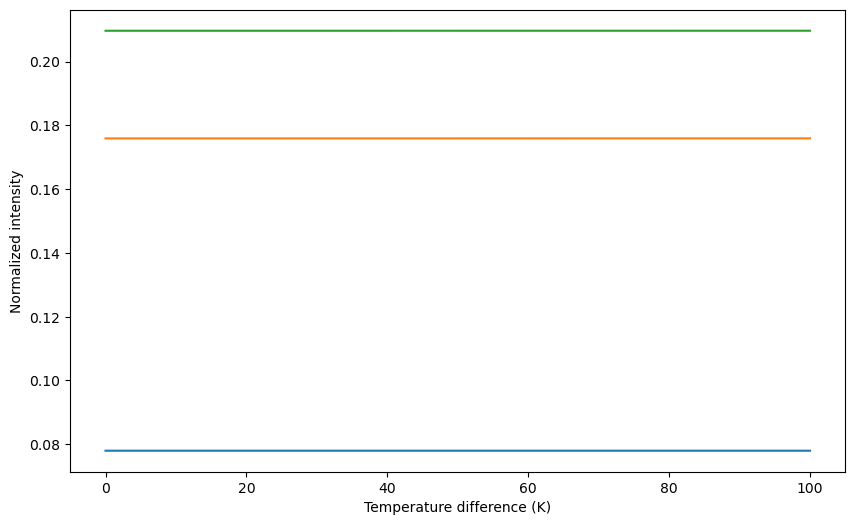

In [3]:
temps = np.linspace(0, 100, 11)
output_A, output_B, output_C = [], [], []
row_A, row_B, row_C = [], [], []
wav_str = f"{wav:.3f}".replace('.', 'p')
norm_dir = r"C:\\Users\\runner\\ActivePIC\\StraightWaveguide\\StraightWaveguide_scan_Wav\\"
norm_filename = norm_dir+f"StraightWaveguide_scan_Wav{wav_str}.mon"
norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
norm = norm_mon[-1, 1]
for temp in temps:
    temp_str = f"{temp:.3f}".replace('.', 'p')
    filename = save_dir+f"\\Device11_4a_1x3Tricoupler_scan_Wav{wav_str}_Temp{temp_str}.mon"
    sim = np.genfromtxt(filename, skip_header=5)
    row_A.append(sim[-1,1]/norm)
    row_B.append(sim[-1,2]/norm)
    row_C.append(sim[-1,3]/norm)      
output_A, output_B, output_C = np.array(row_A), np.array(row_B), np.array(row_C)

plt.figure(figsize=(10,6))
plt.plot(temps, output_A, label='Output A')
plt.plot(temps, output_B, label='Output B')
plt.plot(temps, output_C, label='Output C')
plt.xlabel('Temperature difference (K)')
plt.ylabel('Normalized intensity')
plt.legend
plt.show()

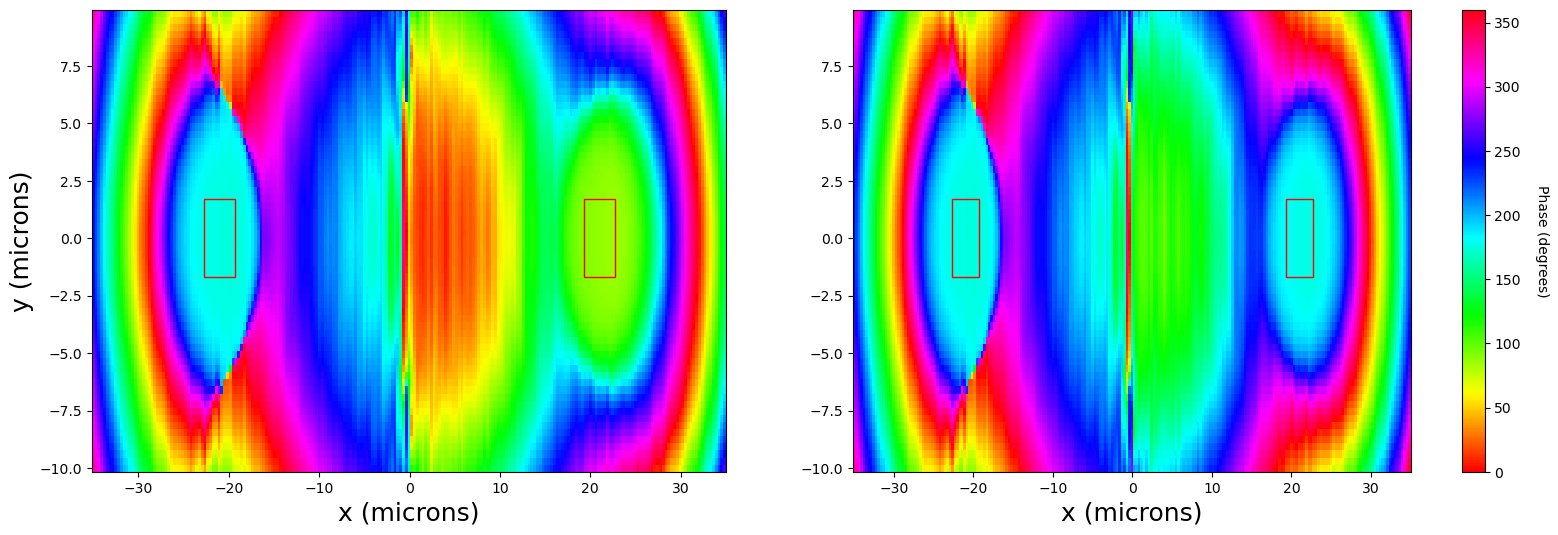

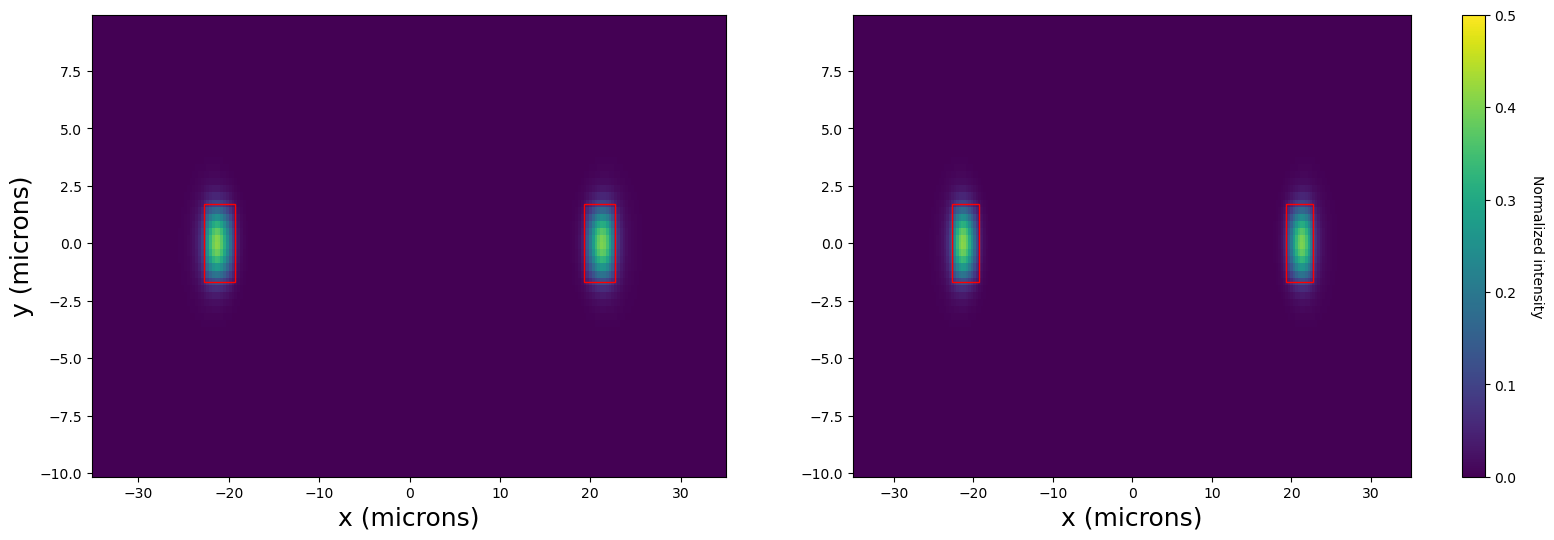

In [35]:
field = np.genfromtxt(input_filename, skip_header=4)
n_rows, n_cols = np.shape(field)
field_amp, field_phase = field[:, ::2].T, field[:, 1::2].T
x_line = linecache.getline(input_filename, 3)
y_line = linecache.getline(input_filename, 4)
x_line_split = x_line.split(' ')
y_line_split = y_line.split(' ')
x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))

# Apply phase shift to input field
field_x = abs(x-tricoupler_right_x) < waveguide_width/2.
field_y = abs(y) < waveguide_height/2. 
field_phase_shifted = np.copy(field_phase)
field_phase_shifted[:, int(int(x_line_split[0])/2):] = (field_phase_shifted[:, int(int(x_line_split[0])/2):] + 90)%360

field = field_amp*np.exp(1j*field_phase*np.pi/180)
intensity = np.absolute(field)**2.
field_shifted = field_amp*np.exp(1j*field_phase_shifted*np.pi/180)
intensity_shifted = np.absolute(field_shifted)**2.

fig, ax = plt.subplots(1, 2, figsize=(18,6))
im = ax[0].pcolormesh(x, y, field_phase, vmin=0, vmax=360, cmap='hsv')
im = ax[1].pcolormesh(x, y, field_phase_shifted, vmin=0, vmax=360, cmap='hsv')
for i in range(2):
    square_left = patches.Rectangle((tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                linewidth=1, edgecolor='r', facecolor='none')
    square_right = patches.Rectangle((tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                 linewidth=1, edgecolor='r', facecolor='none')
    ax[i].add_patch(square_left)
    ax[i].add_patch(square_right)
    ax[i].set_xlabel(f"x (microns)", fontsize=18)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Phase (degrees)', rotation=270, labelpad=20)
ax[0].set_ylabel(f"y (microns)", fontsize=18)
plt.show()


fig, ax = plt.subplots(1, 2, figsize=(18,6))
im = ax[0].pcolormesh(x, y, intensity, vmin=0, vmax=0.5)
im = ax[1].pcolormesh(x, y, intensity_shifted, vmin=0, vmax=0.5)
for i in range(2):
    square_left = patches.Rectangle((tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                linewidth=1, edgecolor='r', facecolor='none')
    square_right = patches.Rectangle((tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                 linewidth=1, edgecolor='r', facecolor='none')
    ax[i].add_patch(square_left)
    ax[i].add_patch(square_right)
    ax[i].set_xlabel(f"x (microns)", fontsize=18)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Normalized intensity', rotation=270, labelpad=20)
ax[0].set_ylabel(f"y (microns)", fontsize=18)
plt.show()

# Plot all outputs

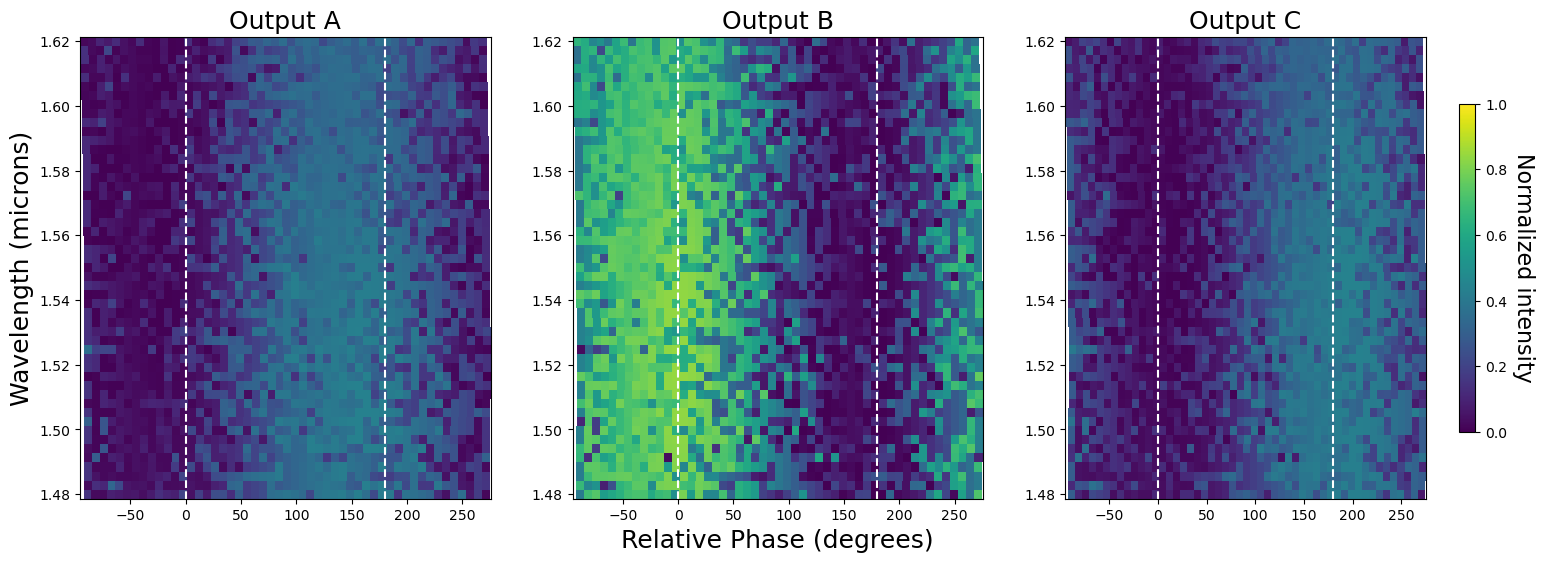

In [8]:
from scipy.stats import binned_statistic_2d

working_dir = r"C:\\Users\\runner\\ActivePIC\\Device11_4a_1x3Tricoupler\\"
save_dir = working_dir+"Device11_4a_1x3Tricoupler_scan_Wav_Phase"
input_dir =  r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\2x2MMI_OneInput_scan_Wav\\"
norm_dir = r"C:\\Users\\runner\\ActivePIC\\StraightWaveguide\\StraightWaveguide_scan_Wav\\"
# monitor_files = glob.glob(save_dir+'//*[0-9].mon')
# data = []
# for filename in monitor_files:
#     sim = np.genfromtxt(filename, skip_header=5)
#     wav, phase = float(filename.split('Wav')[-1].split('_')[0].replace('p', '.')), float(filename.split('Phase')[-1].split('.')[0].replace('p', '.'))
#     data.append([wav, phase, sim[-1,1], sim[-1,2], sim[-1,3]])
# data = np.array(data)

# phase_bins, wav_bins = np.linspace(data[:,1].min(), data[:,1].max(), len(list(set(data[:,1])))+1), np.linspace(data[:,0].min(), data[:,0].max(), len(list(set(data[:,0])))+1)
# output_A, _, _, _ = binned_statistic_2d(data[:,1], data[:,0], data[:,2], statistic='mean', bins=[phase_bins, wav_bins])
# output_A = output_A.T
# output_B, _, _, _ = binned_statistic_2d(data[:,1], data[:,0], data[:,3], statistic='mean', bins=[phase_bins, wav_bins])
# output_B = output_B.T
# output_C, _, _, _ = binned_statistic_2d(data[:,1], data[:,0], data[:,4], statistic='mean', bins=[phase_bins, wav_bins])
# output_C = output_C.T

phases = np.linspace(0, 360, 51)
wavs = np.linspace(1.48, 1.62, 51)

phases_rel, output_A, output_B, output_C = [], [], [], []
for wav in wavs:
    row_phase, row_A, row_B, row_C = [], [], [], []
    wav_str = f"{wav:.3f}".replace('.', 'p')
    input_filename = input_dir+f"2x2MMI_OneInput_scan_Wav{wav_str}.mon"
    input_mon = np.genfromtxt(input_filename, delimiter='', skip_header=5)
    input_phase_rel = input_mon[-1,4] - input_mon[-1,3]
    norm_filename = norm_dir+f"StraightWaveguide_scan_Wav{wav_str}.mon"
    norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
    norm = norm_mon[-1, 1]
    for phase in phases:
        phase_str = f"{phase:.3f}".replace('.', 'p')
        filename = save_dir+f"\\Device11_4a_1x3Tricoupler_scan_Wav{wav_str}_Phase{phase_str}.mon"
        sim = np.genfromtxt(filename, skip_header=5)
        row_A.append(sim[-1,1]/norm)
        row_B.append(sim[-1,2]/norm)
        row_C.append(sim[-1,3]/norm)
        row_phase.append(input_phase_rel+phase)        
    phases_rel.append(row_phase)
    output_A.append(row_A)
    output_B.append(row_B)
    output_C.append(row_C)
output_A, output_B, output_C = np.array(output_A), np.array(output_B), np.array(output_C)
        
vmin, vmax = 0, 1
fig, ax = plt.subplots(1, 3, figsize=(18,6))
im = ax[0].pcolormesh(phases_rel, wavs, output_A, vmin=vmin, vmax=vmax)
im = ax[1].pcolormesh(phases_rel, wavs, output_B, vmin=vmin, vmax=vmax)
im = ax[2].pcolormesh(phases_rel, wavs, output_C, vmin=vmin, vmax=vmax)
for i in range(3):
    ax[i].axvline(0, linestyle='dashed', color='white')
    ax[i].axvline(180, linestyle='dashed', color='white')
ax[0].set_title('Output A', fontsize=18)
ax[1].set_title('Output B', fontsize=18)
ax[2].set_title('Output C', fontsize=18)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Normalized intensity', rotation=270, labelpad=20, fontsize=16)
ax[1].set_xlabel(f"Relative Phase (degrees)", fontsize=18)
ax[0].set_ylabel(f"Wavelength (microns)", fontsize=18)
plt.show()

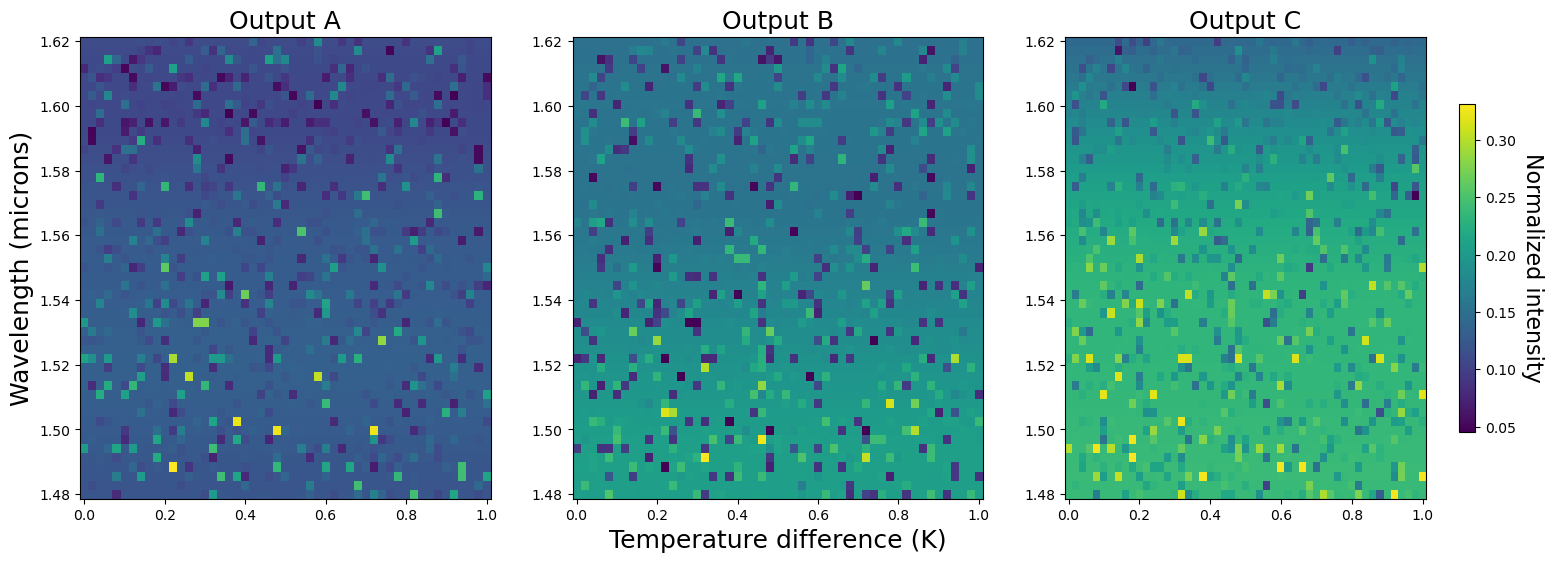

In [15]:
from scipy.stats import binned_statistic_2d

working_dir = r"C:\\Users\\runner\\ActivePIC\\Device11_4a_1x3Tricoupler\\"
save_dir = working_dir+"Device11_4a_1x3Tricoupler_scan_Wav_Temp"
input_dir =  r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\2x2MMI_OneInput_scan_Wav\\"
norm_dir = r"C:\\Users\\runner\\ActivePIC\\StraightWaveguide\\StraightWaveguide_scan_Wav\\"
# monitor_files = glob.glob(save_dir+'//*[0-9].mon')
# data = []
# for filename in monitor_files:
#     sim = np.genfromtxt(filename, skip_header=5)
#     wav, phase = float(filename.split('Wav')[-1].split('_')[0].replace('p', '.')), float(filename.split('Phase')[-1].split('.')[0].replace('p', '.'))
#     data.append([wav, phase, sim[-1,1], sim[-1,2], sim[-1,3]])
# data = np.array(data)

# phase_bins, wav_bins = np.linspace(data[:,1].min(), data[:,1].max(), len(list(set(data[:,1])))+1), np.linspace(data[:,0].min(), data[:,0].max(), len(list(set(data[:,0])))+1)
# output_A, _, _, _ = binned_statistic_2d(data[:,1], data[:,0], data[:,2], statistic='mean', bins=[phase_bins, wav_bins])
# output_A = output_A.T
# output_B, _, _, _ = binned_statistic_2d(data[:,1], data[:,0], data[:,3], statistic='mean', bins=[phase_bins, wav_bins])
# output_B = output_B.T
# output_C, _, _, _ = binned_statistic_2d(data[:,1], data[:,0], data[:,4], statistic='mean', bins=[phase_bins, wav_bins])
# output_C = output_C.T

temps = np.linspace(0, 1, 51)
wavs = np.linspace(1.48, 1.62, 51)#[::5]
output_A, output_B, output_C = [], [], []
for wav in wavs:
    row_A, row_B, row_C = [], [], []
    wav_str = f"{wav:.3f}".replace('.', 'p')
    norm_filename = norm_dir+f"StraightWaveguide_scan_Wav{wav_str}.mon"
    norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
    norm = norm_mon[-1, 1]
    for temp in temps:
        temp_str = f"{temp:.3f}".replace('.', 'p')
        filename = save_dir+f"\\Device11_4a_1x3Tricoupler_scan_Wav{wav_str}_Temp{temp_str}.mon"
        sim = np.genfromtxt(filename, skip_header=5)
        row_A.append(sim[-1,1]/norm)
        row_B.append(sim[-1,2]/norm)
        row_C.append(sim[-1,3]/norm)      
    output_A.append(row_A)
    output_B.append(row_B)
    output_C.append(row_C)
output_A, output_B, output_C = np.array(output_A), np.array(output_B), np.array(output_C)
        
# vmin, vmax = 0, 1
fig, ax = plt.subplots(1, 3, figsize=(18,6))
im = ax[0].pcolormesh(temps, wavs, output_A)#, vmin=vmin, vmax=vmax)
im = ax[1].pcolormesh(temps, wavs, output_B)#, vmin=vmin, vmax=vmax)
im = ax[2].pcolormesh(temps, wavs, output_C)#, vmin=vmin, vmax=vmax)
ax[0].set_title('Output A', fontsize=18)
ax[1].set_title('Output B', fontsize=18)
ax[2].set_title('Output C', fontsize=18)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Normalized intensity', rotation=270, labelpad=20, fontsize=16)
ax[1].set_xlabel(f"Temperature difference (K)", fontsize=18)
ax[0].set_ylabel(f"Wavelength (microns)", fontsize=18)
plt.show()

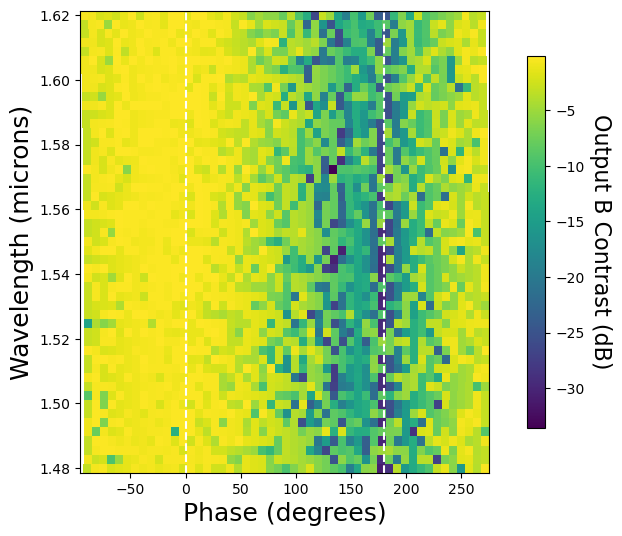

In [9]:
contrast = 10*np.log10(output_B/(output_A+output_B+output_C))

fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(phases_rel, wavs, contrast)
plt.axvline(0, linestyle='dashed', color='white')
plt.axvline(180, linestyle='dashed', color='white')
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Output B Contrast (dB)', rotation=270, labelpad=20, fontsize=16)
plt.xlabel(f"Phase (degrees)", fontsize=18)
plt.ylabel(f"Wavelength (microns)", fontsize=18)
plt.show()

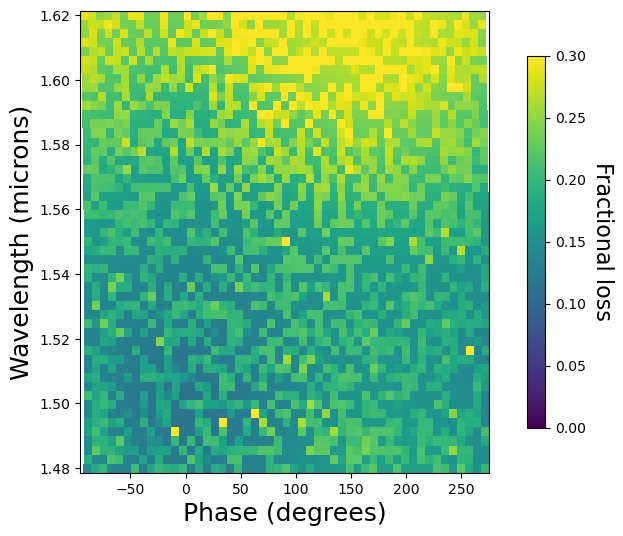

In [13]:
vmin, vmax = 0, 0.3
fig, ax = plt.subplots(1, 1, figsize=(6,6))
im = plt.pcolormesh(phases_rel, wavs, 1 - (output_A+output_B+output_C), vmin=vmin, vmax=vmax)
cbar = plt.colorbar(im, fraction=0.04, pad=0.08)
cbar.set_label('Fractional loss', rotation=270, labelpad=20, fontsize=16)
plt.xlabel(f"Phase (degrees)", fontsize=18)
plt.ylabel(f"Wavelength (microns)", fontsize=18)
plt.show()

In [14]:
norm

0.7639162